# Verificación de la simulación (sección 7.1)

Dueña: Aleja. Este cuaderno audita los tres escenarios con los datos EMC disponibles y la construcción reproducible del proyecto. Las correlaciones y participaciones se describen como resultados del panel simulado; no se usan para seleccionar modelos.

La construcción regional por línea es `L(l,t) × F(d,t) × eta(d,l,t)`. Las salidas se guardan en `results/tablas/` y `results/figuras/`, las rutas configuradas del repositorio.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

raiz = Path.cwd()
if not (raiz / "src").is_dir():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.config import (
    DEPARTAMENTOS,
    ESCENARIOS,
    LINEA_OBJETIVO,
    LINEAS,
    PESOS_DEPTO,
    RHO,
    RUTA_FIGURAS,
    RUTA_TABLAS,
    SEMILLA,
)
from src.datos.emc import leer_lineas_nacional
from src.datos.panel import _construir_panel_y_componentes
from src.evaluacion.agregacion import agregar_nacional
from src.figuras import aplicar_estilo, guardar_figura

aplicar_estilo()
RUTA_TABLAS.mkdir(parents=True, exist_ok=True)
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)
lineas_nacionales = leer_lineas_nacional()
paneles = {}
componentes = {}
auditoria = {}

for nombre, sigma in ESCENARIOS.items():
    paneles[nombre], componentes[nombre] = _construir_panel_y_componentes(nombre)
    auditoria[nombre] = paneles[nombre].merge(
        componentes[nombre],
        on=["fecha", "departamento", "linea_codigo", "linea"],
        validate="one_to_one",
    )
    auditoria[nombre]["log_eta"] = np.log(
        auditoria[nombre]["indice_ventas_real"]
        / (auditoria[nombre]["L"] * auditoria[nombre]["F"])
    )

print(f"Semilla {SEMILLA}; persistencia objetivo RHO={RHO:.2f}; paneles: "
      + ", ".join(f"{k}: {len(v):,} filas" for k, v in paneles.items()))


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\aleja_z3j4wvb\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Semilla 42; persistencia objetivo RHO=0.60; paneles: bajo: 5,096 filas, central: 5,096 filas, alto: 5,096 filas


## 1. Magnitud

Se calcula la desviación estándar poblacional de `log(eta)` recuperado del índice y de los componentes de auditoría (`log(indice / (L × F))`). El criterio de magnitud sigue las pruebas del proyecto: desviación dentro de ±20 % del sigma configurado. La línea vertical discontinua marca cada objetivo.


,verificacion,objetivo,obtenido,escenario,cumple,detalle
0,Magnitud de log(eta),sigma=2.00% (tolerancia ±20%),0.019038,bajo,True,desviación estándar poblacional; sigma=0.0200
1,Magnitud de log(eta),sigma=7.00% (tolerancia ±20%),0.066612,central,True,desviación estándar poblacional; sigma=0.0700
2,Magnitud de log(eta),sigma=13.00% (tolerancia ±20%),0.123696,alto,True,desviación estándar poblacional; sigma=0.1300


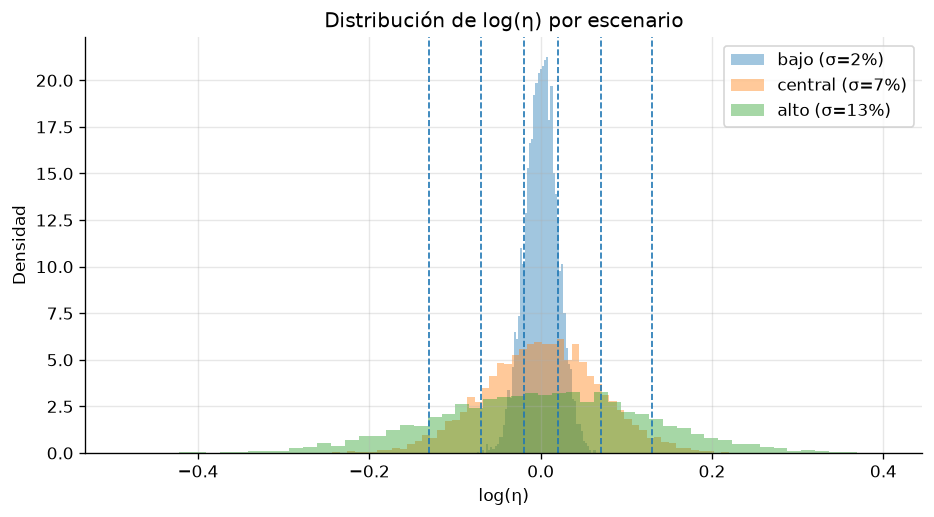

In [2]:
resultados = []
magnitudes = {}
for escenario, sigma in ESCENARIOS.items():
    log_eta = auditoria[escenario]["log_eta"]
    obtenido = log_eta.std(ddof=0)
    magnitudes[escenario] = log_eta
    resultados.append({
        "verificacion": "Magnitud de log(eta)",
        "objetivo": f"sigma={sigma:.2%} (tolerancia ±20%)",
        "obtenido": obtenido,
        "escenario": escenario,
        "cumple": bool(0.8 * sigma <= obtenido <= 1.2 * sigma),
        "detalle": f"desviación estándar poblacional; sigma={sigma:.4f}",
    })

tabla_magnitud = pd.DataFrame(resultados[-len(ESCENARIOS):])
display(tabla_magnitud)
fig, ax = plt.subplots(figsize=(9, 4.5))
for escenario, sigma in ESCENARIOS.items():
    valores = magnitudes[escenario].to_numpy()
    ax.hist(valores, bins=55, density=True, alpha=0.42, label=f"{escenario} (σ={sigma:.0%})")
    ax.axvline(sigma, linestyle="--", linewidth=1)
    ax.axvline(-sigma, linestyle="--", linewidth=1)
ax.set(title="Distribución de log(η) por escenario", xlabel="log(η)", ylabel="Densidad")
ax.legend()
plt.show()


## 2. Persistencia

Para cada una de las 56 series departamento × línea se calcula la correlación de Pearson entre `log(eta)` en los meses consecutivos t y t−1. Se muestra la distribución por escenario, el objetivo de diseño 0,60 y el rango observado de referencia 0,50–0,66. Ese rango es descriptivo, no un intervalo de confianza. El cumplimiento usa la tolerancia de diseño 0,60 ± 0,10.


,verificacion,objetivo,obtenido,escenario,cumple,detalle
0,Persistencia AR(1),media=0.60 ±0.10; referencia observada 0.50–0.66,0.562993,bajo,True,56 series; rango obtenido 0.396–0.756
1,Persistencia AR(1),media=0.60 ±0.10; referencia observada 0.50–0.66,0.562584,central,True,56 series; rango obtenido 0.395–0.755
2,Persistencia AR(1),media=0.60 ±0.10; referencia observada 0.50–0.66,0.561955,alto,True,56 series; rango obtenido 0.394–0.754


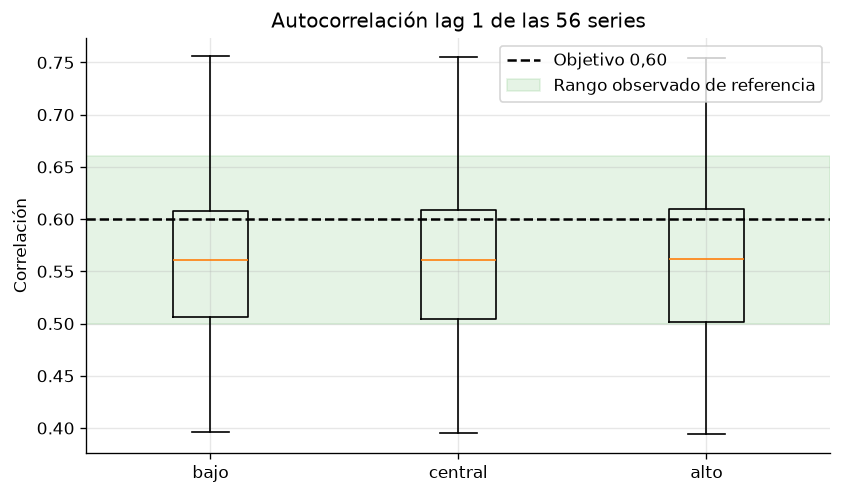

In [3]:
autocorrelaciones = {}
filas_ac = []
for escenario in ESCENARIOS:
    tabla = auditoria[escenario].pivot(
        index="fecha", columns=["departamento", "linea_codigo"], values="log_eta"
    ).sort_index()
    valores = tabla.corrwith(tabla.shift(1)).dropna()
    autocorrelaciones[escenario] = valores
    media_ac = valores.mean()
    filas_ac.append({
        "verificacion": "Persistencia AR(1)",
        "objetivo": "media=0.60 ±0.10; referencia observada 0.50–0.66",
        "obtenido": media_ac,
        "escenario": escenario,
        "cumple": bool(abs(media_ac - RHO) <= 0.1),
        "detalle": f"56 series; rango obtenido {valores.min():.3f}–{valores.max():.3f}",
    })
resultados.extend(filas_ac)
display(pd.DataFrame(filas_ac))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([autocorrelaciones[s].to_numpy() for s in ESCENARIOS])
ax.set_xticks(range(1, len(ESCENARIOS) + 1), list(ESCENARIOS))
ax.axhline(RHO, color="black", linestyle="--", label="Objetivo 0,60")
ax.axhspan(0.50, 0.66, alpha=0.12, color="tab:green", label="Rango observado de referencia")
ax.set(title="Autocorrelación lag 1 de las 56 series", ylabel="Correlación")
ax.legend()
plt.show()


## 3. Conservación nacional

Se agrega la línea objetivo con `agregar_nacional`, que aplica `PESOS_DEPTO`, y se compara con la serie oficial EMC de `leer_lineas_nacional`. El criterio numérico es diferencia absoluta máxima menor o igual a 1e-6 puntos de índice.


In [4]:
nacional_objetivo = (
    lineas_nacionales[lineas_nacionales["linea"] == LINEA_OBJETIVO]
    .set_index("fecha")["L"]
    .sort_index()
)
series_nacionales = {}
filas_conservacion = []
for escenario, panel in paneles.items():
    reconstruida = agregar_nacional(panel, "indice_ventas_real", linea=LINEA_OBJETIVO)
    reconstruida = reconstruida.reindex(nacional_objetivo.index)
    series_nacionales[escenario] = reconstruida
    error = float((reconstruida - nacional_objetivo).abs().max())
    filas_conservacion.append({
        "verificacion": "Conservación nacional muebles",
        "objetivo": "error absoluto máximo ≤1e-6",
        "obtenido": error,
        "escenario": escenario,
        "cumple": bool(error <= 1e-6),
        "detalle": "pesos PESOS_DEPTO; unidades: puntos de índice",
    })
resultados.extend(filas_conservacion)
display(pd.DataFrame(filas_conservacion))


,verificacion,objetivo,obtenido,escenario,cumple,detalle
0,Conservación nacional muebles,error absoluto máximo ≤1e-6,2.842171e-14,bajo,True,pesos PESOS_DEPTO; unidades: puntos de índice
1,Conservación nacional muebles,error absoluto máximo ≤1e-6,2.842171e-14,central,True,pesos PESOS_DEPTO; unidades: puntos de índice
2,Conservación nacional muebles,error absoluto máximo ≤1e-6,2.842171e-14,alto,True,pesos PESOS_DEPTO; unidades: puntos de índice


## 4. Relaciones entre líneas

No existe en los anexos una serie observada de ventas EMC para cada combinación departamento × línea: el DANE publica las líneas a nivel nacional y un único factor regional del grupo hogar. Para describir lo que induce el panel, se calculan correlaciones Pearson entre los cambios mensuales de `log(indice_ventas_real)` de cada par de líneas dentro del mismo departamento (28 pares × 7 departamentos). Se informa la media de los 196 pares y el rango de medias departamentales.

El rango 0,07–0,30 se conserva como referencia observada indicada en la guía, no como intervalo de confianza. Esta comparación es descriptiva del panel simulado y no constituye validación contra correlaciones regionales observadas por línea.


In [5]:
filas_relaciones = []
correlaciones_lineas = {}
for escenario, panel in paneles.items():
    matriz = panel.pivot(
        index="fecha", columns=["departamento", "linea_codigo"], values="indice_ventas_real"
    ).sort_index()
    cambios = np.log(matriz).diff().dropna()
    pares = []
    medias_depto = {}
    for departamento in DEPARTAMENTOS:
        cols = [(departamento, codigo) for codigo in LINEAS]
        corr = cambios[cols].corr()
        valores = corr.to_numpy()[np.triu_indices(len(cols), k=1)]
        pares.extend(valores.tolist())
        medias_depto[departamento] = float(np.mean(valores))
    correlaciones_lineas[escenario] = pares
    media_pares = float(np.mean(pares))
    dentro_referencia = 0.07 <= media_pares <= 0.30
    filas_relaciones.append({
        "verificacion": "Correlación de cambios entre líneas",
        "objetivo": "media en rango descriptivo 0.07–0.30; no es IC",
        "obtenido": media_pares,
        "escenario": escenario,
        "cumple": bool(dentro_referencia),
        "detalle": ("196 correlaciones de pares; rango de medias departamentales "
                    f"{min(medias_depto.values()):.3f}–{max(medias_depto.values()):.3f}; "
                    f"pares en 0.07–0.30: {sum(0.07 <= x <= 0.30 for x in pares)}/196; "
                    f"rango de pares {min(pares):.3f}–{max(pares):.3f}; "
                    "referencia no validable contra datos regionales observados"),
    })
resultados.extend(filas_relaciones)
display(pd.DataFrame(filas_relaciones))


,verificacion,objetivo,obtenido,escenario,cumple,detalle
0,Correlación de cambios entre líneas,media en rango descriptivo 0.07–0.30; no es IC,0.645713,bajo,False,196 correlaciones de pares; rango de medias de...
1,Correlación de cambios entre líneas,media en rango descriptivo 0.07–0.30; no es IC,0.593752,central,False,196 correlaciones de pares; rango de medias de...
2,Correlación de cambios entre líneas,media en rango descriptivo 0.07–0.30; no es IC,0.496081,alto,False,196 correlaciones de pares; rango de medias de...


## 5. Proporciones departamentales

Para muebles, cada mes se calcula la contribución ponderada `peso_d × índice_d` como fracción del total nacional; se promedia esa participación mensual y se compara con el peso base 2019 de `PESOS_DEPTO`. La tolerancia 1e-6 es numérica. Estos pesos son coeficientes de agregación, no participaciones que deban permanecer constantes: los factores regionales y eta pueden producir diferencias reales. Por eso se informa el resultado de la comparación sin modificar la simulación.


,escenario,departamento,peso_base_2019,participacion_promedio,diferencia
0,bajo,Antioquia,0.170438,0.170213,-0.000225
1,bajo,Atlantico,0.057136,0.052138,-0.004998
2,bajo,Bogota,0.225540,0.239159,0.013619
3,bajo,Cundinamarca,0.049960,0.056793,0.006833
4,bajo,Santander,0.043320,0.041621,-0.001699
5,bajo,Valle del Cauca,0.120603,0.107778,-0.012825
6,bajo,Otros departamentos,0.333003,0.332298,-0.000705
7,central,Antioquia,0.170438,0.169301,-0.001137
8,central,Atlantico,0.057136,0.051899,-0.005237
9,central,Bogota,0.225540,0.237795,0.012255


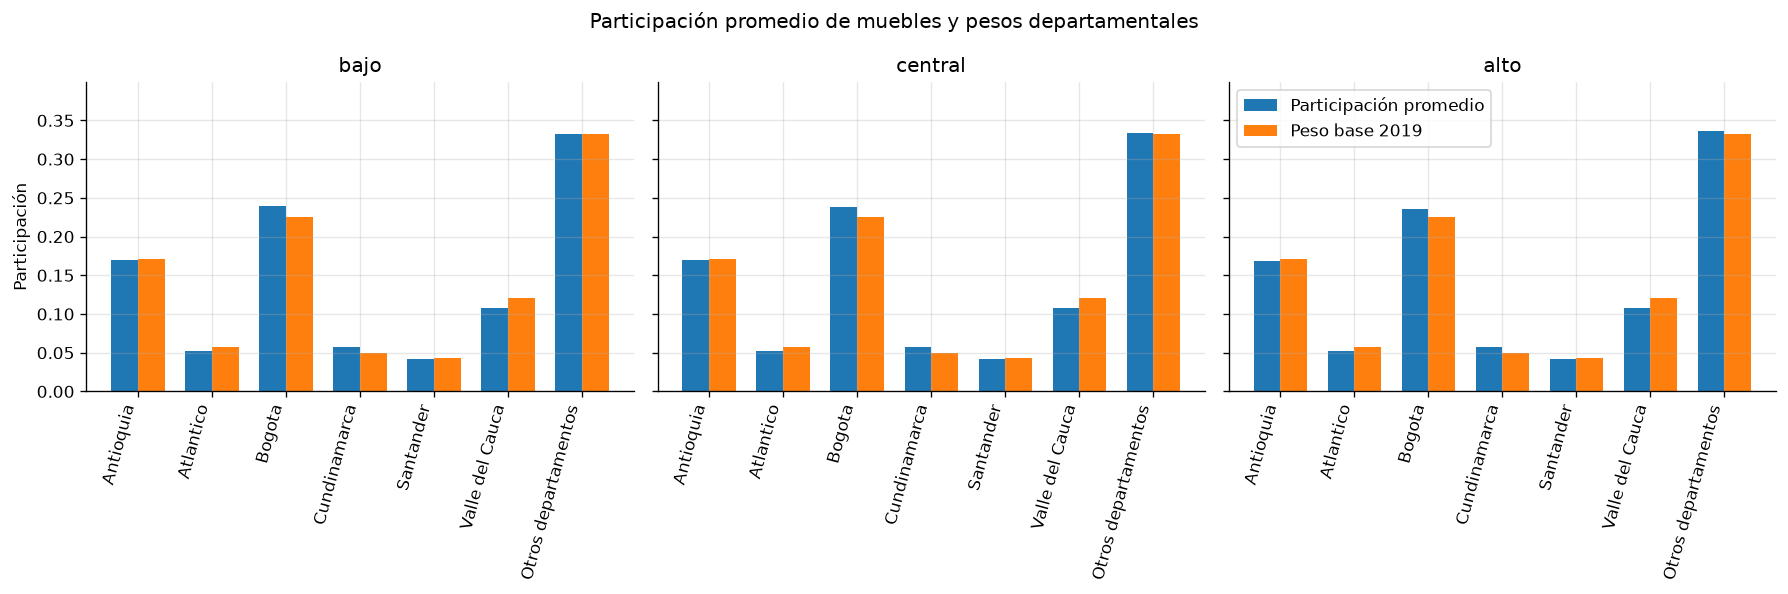

In [6]:
filas_proporciones = []
proporciones = {}
for escenario, panel in paneles.items():
    muebles = panel[panel["linea"] == LINEA_OBJETIVO].copy()
    muebles["peso"] = muebles["departamento"].map(PESOS_DEPTO)
    muebles["contribucion"] = muebles["peso"] * muebles["indice_ventas_real"]
    total_mes = muebles.groupby("fecha")["contribucion"].transform("sum")
    muebles["participacion"] = muebles["contribucion"] / total_mes
    shares = muebles.groupby("departamento")["participacion"].mean().reindex(DEPARTAMENTOS)
    proporciones[escenario] = shares
    for departamento in DEPARTAMENTOS:
        diferencia = float(shares[departamento] - PESOS_DEPTO[departamento])
        filas_proporciones.append({
            "verificacion": "Proporción departamental promedio muebles",
            "objetivo": float(PESOS_DEPTO[departamento]),
            "obtenido": float(shares[departamento]),
            "escenario": escenario,
            "cumple": bool(abs(diferencia) <= 1e-6),
            "detalle": f"{departamento}; diferencia={diferencia:+.6g}; tolerancia numérica 1e-6",
        })
resultados.extend(filas_proporciones)
tabla_proporciones = pd.DataFrame(filas_proporciones)
tabla_proporciones_display = pd.DataFrame([
    {
        "escenario": escenario,
        "departamento": departamento,
        "peso_base_2019": PESOS_DEPTO[departamento],
        "participacion_promedio": proporciones[escenario][departamento],
        "diferencia": proporciones[escenario][departamento] - PESOS_DEPTO[departamento],
    }
    for escenario in ESCENARIOS
    for departamento in DEPARTAMENTOS
])
display(tabla_proporciones_display.round(6))
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
x = np.arange(len(DEPARTAMENTOS))
for ax, escenario in zip(axes, ESCENARIOS):
    ax.bar(x - 0.18, [proporciones[escenario][d] for d in DEPARTAMENTOS],
           width=0.36, label="Participación promedio")
    ax.bar(x + 0.18, [PESOS_DEPTO[d] for d in DEPARTAMENTOS],
           width=0.36, label="Peso base 2019")
    ax.set_title(escenario)
    ax.set_xticks(x, DEPARTAMENTOS, rotation=75, ha="right")
    ax.set_ylim(0, max(PESOS_DEPTO.values()) * 1.2)
axes[0].set_ylabel("Participación")
axes[-1].legend()
fig.suptitle("Participación promedio de muebles y pesos departamentales")
fig.tight_layout()
plt.show()


## Resultados consolidados

`cumple` indica el criterio numérico descrito para cada fila. En correlaciones entre líneas, ese indicador solo señala si la media cae en el rango de referencia; por falta de series DANE regionales por línea, no valida la referencia empíricamente. En proporciones, una diferencia respecto al peso base puede ser esperable por `F` y `eta`.


,verificacion,objetivo,obtenido,escenario,cumple,detalle
0,Magnitud de log(eta),sigma=2.00% (tolerancia ±20%),1.903751e-02,bajo,True,desviación estándar poblacional; sigma=0.0200
1,Magnitud de log(eta),sigma=7.00% (tolerancia ±20%),6.661158e-02,central,True,desviación estándar poblacional; sigma=0.0700
2,Magnitud de log(eta),sigma=13.00% (tolerancia ±20%),1.236957e-01,alto,True,desviación estándar poblacional; sigma=0.1300
3,Persistencia AR(1),media=0.60 ±0.10; referencia observada 0.50–0.66,5.629931e-01,bajo,True,56 series; rango obtenido 0.396–0.756
4,Persistencia AR(1),media=0.60 ±0.10; referencia observada 0.50–0.66,5.625841e-01,central,True,56 series; rango obtenido 0.395–0.755
5,Persistencia AR(1),media=0.60 ±0.10; referencia observada 0.50–0.66,5.619552e-01,alto,True,56 series; rango obtenido 0.394–0.754
6,Conservación nacional muebles,error absoluto máximo ≤1e-6,2.842171e-14,bajo,True,pesos PESOS_DEPTO; unidades: puntos de índice
7,Conservación nacional muebles,error absoluto máximo ≤1e-6,2.842171e-14,central,True,pesos PESOS_DEPTO; unidades: puntos de índice
8,Conservación nacional muebles,error absoluto máximo ≤1e-6,2.842171e-14,alto,True,pesos PESOS_DEPTO; unidades: puntos de índice
9,Correlación de cambios entre líneas,media en rango descriptivo 0.07–0.30; no es IC,6.457127e-01,bajo,False,196 correlaciones de pares; rango de medias de...


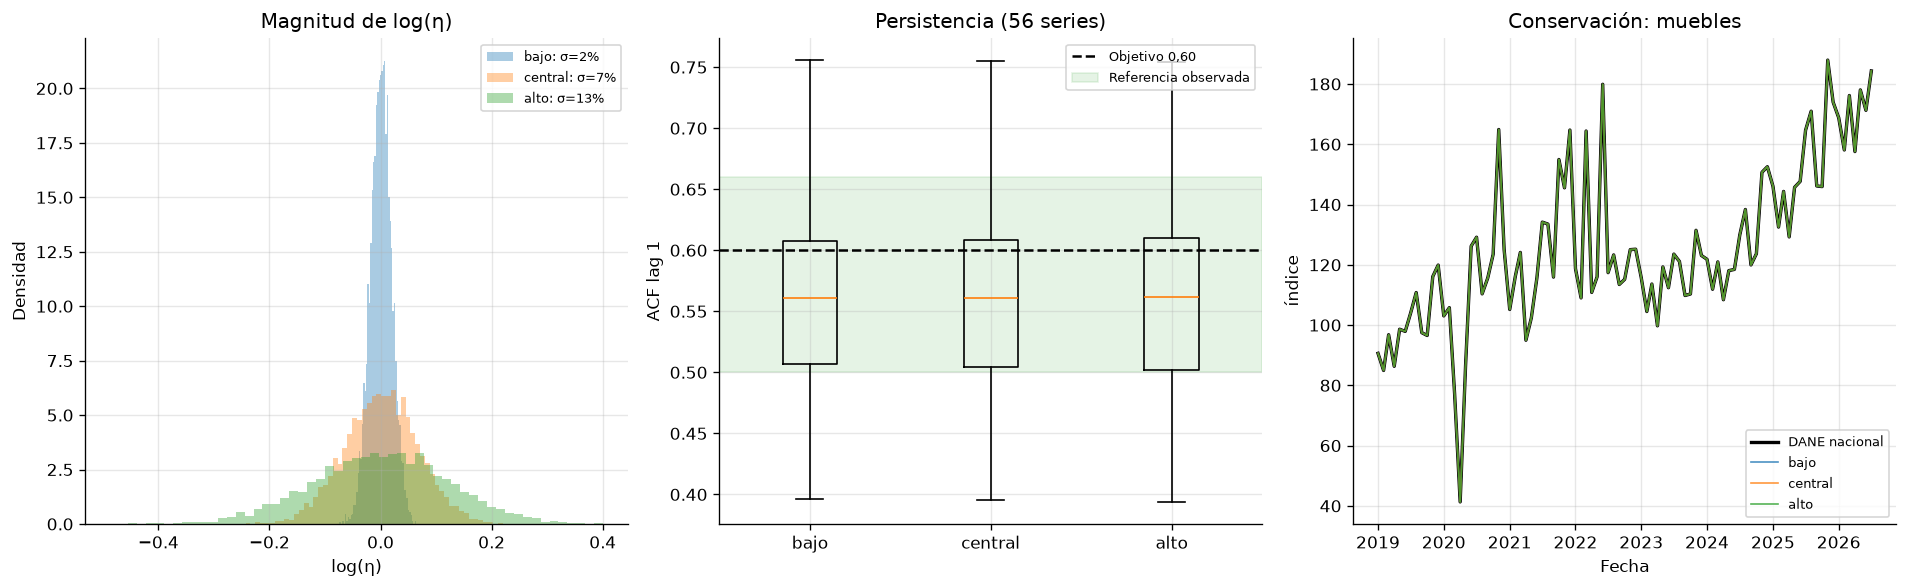

CSV: C:\Projects_U\Machine_L\pronostico-amoblamiento-colombia\results\tablas\verificacion_simulacion.csv
Figura principal: C:\Projects_U\Machine_L\pronostico-amoblamiento-colombia\results\figuras\verificacion_simulacion.png


In [7]:
tabla_resultados = pd.DataFrame(resultados)
columnas = ["verificacion", "objetivo", "obtenido", "escenario", "cumple", "detalle"]
tabla_resultados = tabla_resultados[columnas]
tabla_resultados.to_csv(RUTA_TABLAS / "verificacion_simulacion.csv", index=False)
display(tabla_resultados)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for escenario, sigma in ESCENARIOS.items():
    axes[0].hist(magnitudes[escenario], bins=55, density=True, alpha=0.38,
                 label=f"{escenario}: σ={sigma:.0%}")
axes[0].set(title="Magnitud de log(η)", xlabel="log(η)", ylabel="Densidad")
axes[0].legend(fontsize=8)
axes[1].boxplot([autocorrelaciones[s].to_numpy() for s in ESCENARIOS],
                tick_labels=list(ESCENARIOS))
axes[1].axhline(RHO, color="black", linestyle="--", label="Objetivo 0,60")
axes[1].axhspan(0.50, 0.66, alpha=0.12, color="tab:green", label="Referencia observada")
axes[1].set(title="Persistencia (56 series)", ylabel="ACF lag 1")
axes[1].legend(fontsize=8)
axes[2].plot(nacional_objetivo.index, nacional_objetivo, color="black", linewidth=2,
             label="DANE nacional")
for escenario, serie in series_nacionales.items():
    axes[2].plot(serie.index, serie, linewidth=1, alpha=0.8, label=escenario)
axes[2].set(title="Conservación: muebles", xlabel="Fecha", ylabel="índice")
axes[2].legend(fontsize=8)
fig.tight_layout()
guardar_figura(fig, "verificacion_simulacion")
plt.show()

print(f"CSV: {RUTA_TABLAS / 'verificacion_simulacion.csv'}")
print(f"Figura principal: {RUTA_FIGURAS / 'verificacion_simulacion.png'}")
